# Employee Performance Visualization

## Objective

The charts will help explain the distribution of performance ratings, differences across departments, relationships between employee characteristics and performance, and the results of the machine learning models.

This notebook focuses on the most useful visualizations from the project rather than repeating the complete exploratory data analysis.

## 1. Employee Performance Rating Distribution

This chart shows the number of employees in each performance rating category. Most employees received a rating of 3, while ratings of 2 and 4 were less common.

This imbalance is important when evaluating the machine learning models because a model may perform well on the most common category while struggling to predict the less common categories.


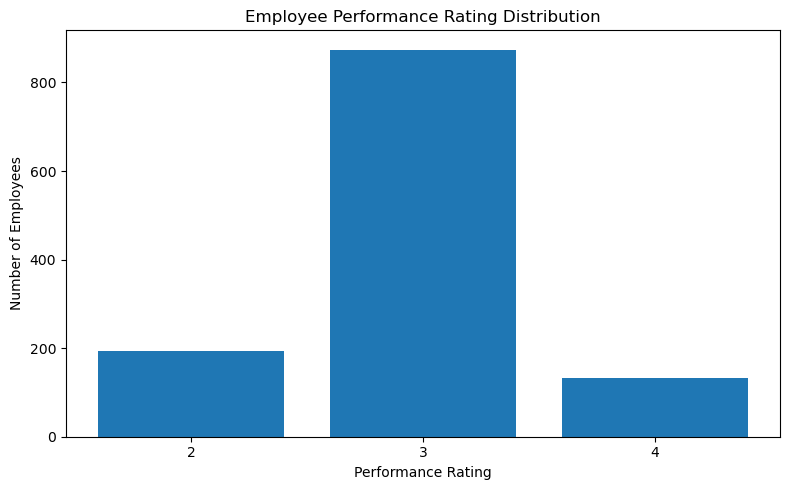

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_path = Path("../../data/processed/employee_performance_processed.csv")
df = pd.read_csv(data_path)

rating_counts = df["PerformanceRating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)

plt.title("Employee Performance Rating Distribution")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

## 2. Average Performance Rating by Department

This chart compares the average employee performance rating across departments. It helps identify differences in average performance between departments and highlights areas that may need further investigation.

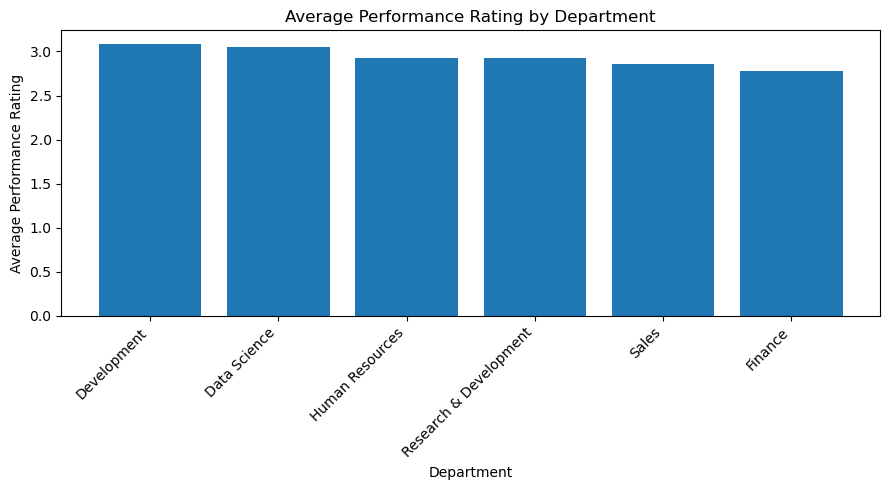

In [6]:
department_performance = df.groupby("EmpDepartment")["PerformanceRating"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(department_performance.index, department_performance.values)

plt.title("Average Performance Rating by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Rating")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## 3. Environment Satisfaction and Performance Rating

This chart compares average performance ratings across employee environment satisfaction levels. It helps us understand whether employees with different satisfaction levels show differences in their average performance ratings.

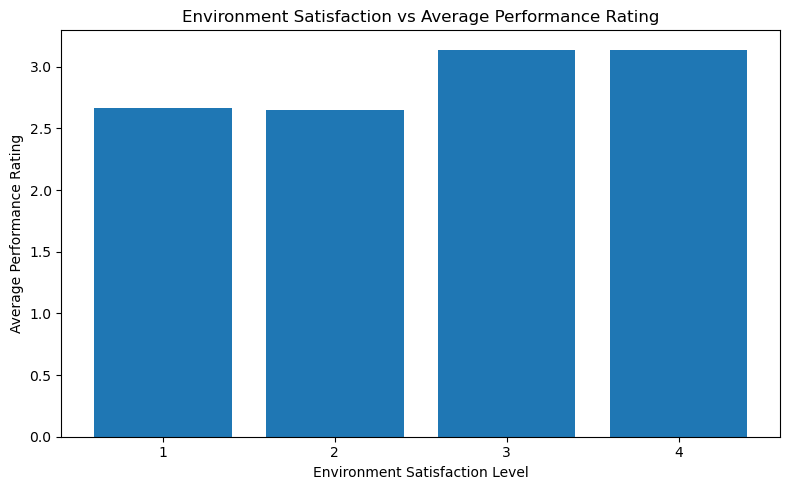

In [11]:
satisfaction_performance = df.groupby("EmpEnvironmentSatisfaction")["PerformanceRating"].mean().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(satisfaction_performance.index.astype(str),satisfaction_performance.values)

plt.title("Environment Satisfaction vs Average Performance Rating")
plt.xlabel("Environment Satisfaction Level")
plt.ylabel("Average Performance Rating")

plt.tight_layout()
plt.show()

## 4. Salary Hike Percentage by Performance Rating

This chart compares the average salary hike percentage for each performance rating category. It helps us understand how salary hikes differ across performance ratings. However, this relationship alone doesn't prove that salary hikes cause better performance.

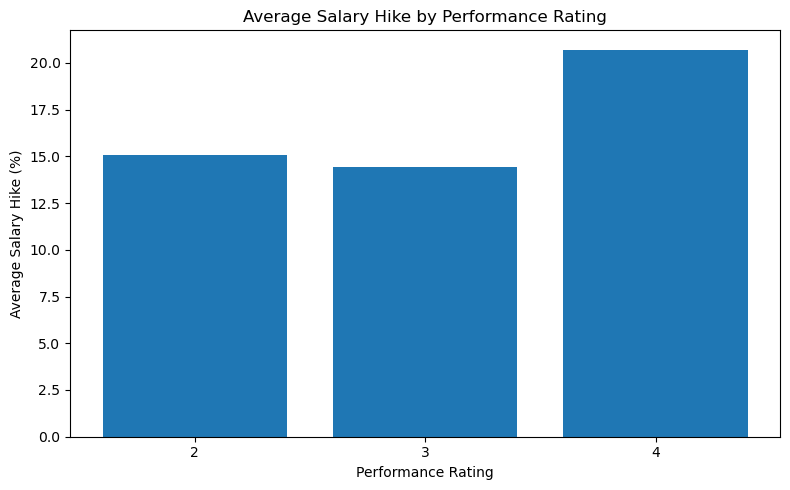

In [12]:
salary_hike = df.groupby("PerformanceRating")["EmpLastSalaryHikePercent"].mean().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(salary_hike.index.astype(str), salary_hike.values)

plt.title("Average Salary Hike by Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Average Salary Hike (%)")

plt.tight_layout()
plt.show()

## 5. Correlation Heatmap

This heatmap shows the correlations between selected numerical features and employee performance rating. It helps identify positive and negative relationships between variables. Correlation does not necessarily mean that one variable causes changes in another.

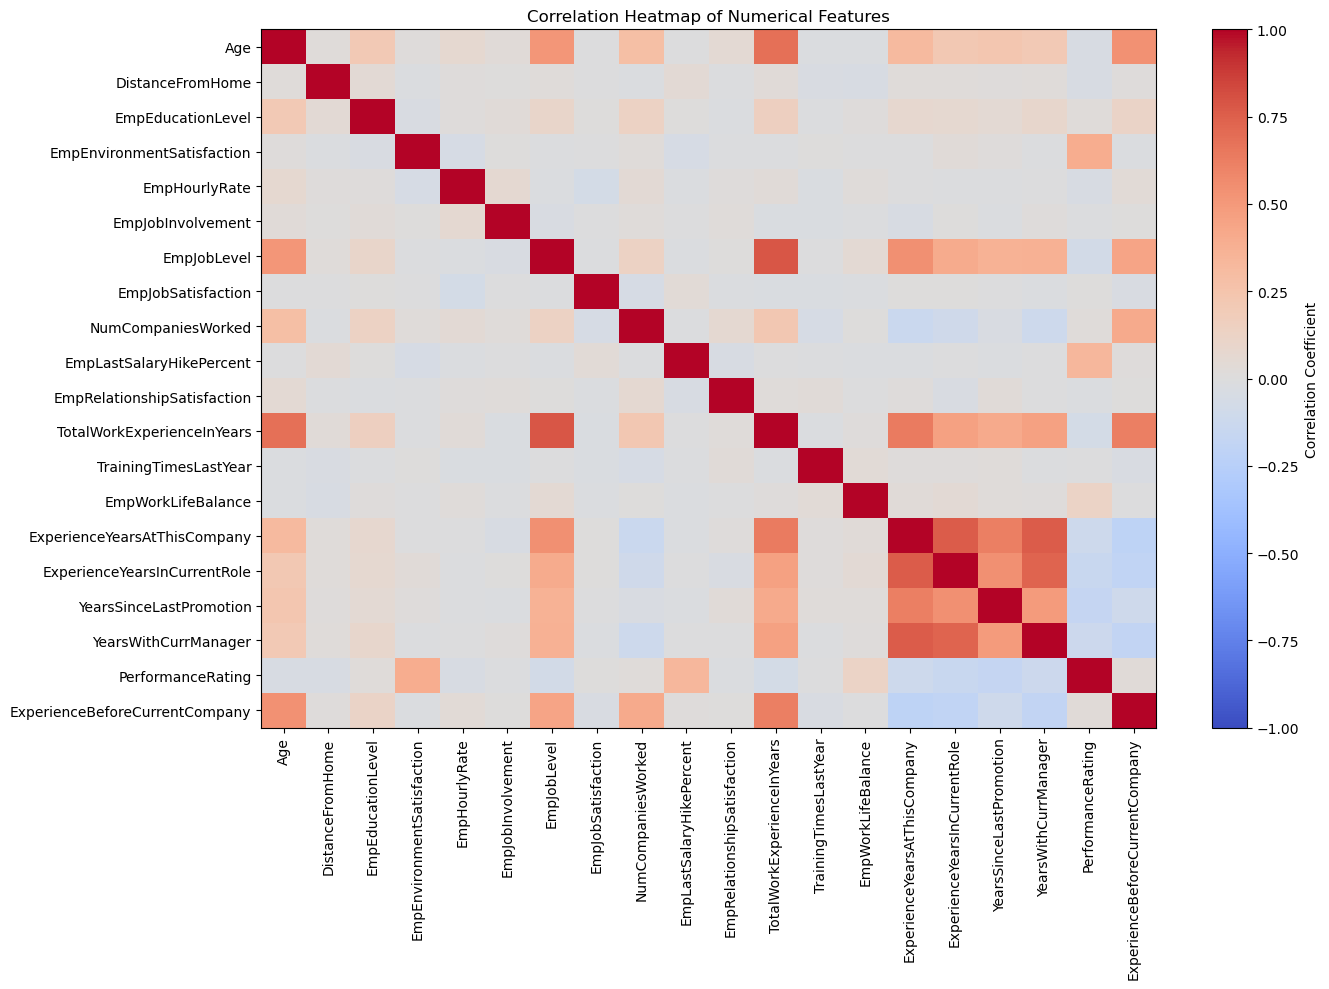

In [13]:
# Select numerical columns for correlation analysis
numerical_data = df.select_dtypes(include="number")

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()

# Create the heatmap
plt.figure(figsize=(14, 10))
plt.imshow(correlation_matrix, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)

plt.colorbar(label="Correlation Coefficient")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## 6. Machine Learning Model Performance Comparison

This chart compares the accuracy of the four machine learning models evaluated in this project: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting. It helps identify which model achieved the highest accuracy on the test dataset.

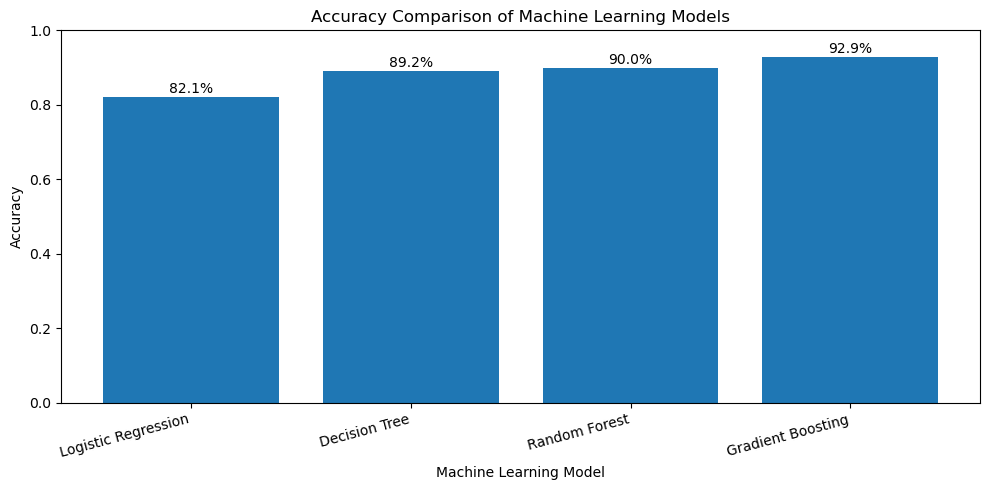

In [15]:
model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
]

accuracy_scores = [0.8208, 0.8917, 0.9000, 0.9292]

plt.figure(figsize=(10, 5))
bars = plt.bar(model_names, accuracy_scores)

for bar, score in zip(bars, accuracy_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{score:.1%}",
        ha="center"
    )

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")

plt.tight_layout()
plt.show()